**Cell 1: Load the data and look at it**

In [1]:
import pandas as pd, numpy as np, json, os
url = "https://raw.githubusercontent.com/ncl-iot-team/CSC8112/main/data/PM2.5_labelled_data.csv"
df = pd.read_csv(url)
print(df.head()); print(df.columns.tolist())
df["Quality"] = df["Quality"].str.strip().str.upper()
print(df["Quality"].value_counts())

      Timestamp   Units Variable                Sensor Name  \
0  1.685580e+12  ugm -3    PM2.5  PER_AIRMON_MONITOR1135100   
1  1.685580e+12  ugm -3    PM2.5  PER_AIRMON_MONITOR1135100   
2  1.685580e+12  ugm -3    PM2.5  PER_AIRMON_MONITOR1135100   
3  1.685580e+12  ugm -3    PM2.5  PER_AIRMON_MONITOR1135100   
4  1.685580e+12  ugm -3    PM2.5  PER_AIRMON_MONITOR1135100   

   Flagged as Suspect Reading  Value Quality  
0                       False  4.273   GREEN  
1                       False  3.483   GREEN  
2                       False  3.713   GREEN  
3                       False  3.813   GREEN  
4                       False  3.885   GREEN  
['Timestamp', 'Units', 'Variable', 'Sensor Name', 'Flagged as Suspect Reading', 'Value', 'Quality']
Quality
GREEN     1027
YELLOW     461
RED         11
Name: count, dtype: int64


**Cell 2: Label encoding, normalisation and the train/test split**

In [2]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
classes = ["GREEN", "YELLOW", "RED"]
le = LabelEncoder().fit(classes)                  # label encoding
y = le.transform(df["Quality"])
X = df[["Value"]].values.astype("float32")
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
mean, std = X_tr.mean(), X_tr.std()               # normalisation
X_tr_n, X_te_n = (X_tr - mean) / std, (X_te - mean) / std
json.dump({"mean": float(mean), "std": float(std), "classes": list(le.classes_)},
          open("scaler.json", "w"))
print(le.classes_, mean, std)

['GREEN' 'RED' 'YELLOW'] 8.739665 6.0615373


**Cell 3: Handle the imbalance and train a Keras Sequential model**

In [3]:
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
w = compute_class_weight("balanced", classes=np.unique(y_tr), y=y_tr)
class_weight = dict(enumerate(w)); print("class weights:", class_weight)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1,)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(X_tr_n, y_tr, epochs=60, batch_size=32, validation_split=0.1,
          class_weight=class_weight, verbose=2)
model.save("model.keras")

class weights: {0: np.float64(0.4868047097036135), 1: np.float64(44.407407407407405), 2: np.float64(1.0831074977416442)}
Epoch 1/60
34/34 - 2s - 73ms/step - accuracy: 0.3466 - loss: 0.8113 - val_accuracy: 0.6917 - val_loss: 1.0274
Epoch 2/60
34/34 - 1s - 21ms/step - accuracy: 0.7331 - loss: 0.7501 - val_accuracy: 0.7750 - val_loss: 0.9549
Epoch 3/60
34/34 - 0s - 6ms/step - accuracy: 0.8415 - loss: 0.6928 - val_accuracy: 0.8583 - val_loss: 0.8732
Epoch 4/60
34/34 - 0s - 5ms/step - accuracy: 0.8916 - loss: 0.6340 - val_accuracy: 0.8750 - val_loss: 0.7787
Epoch 5/60
34/34 - 0s - 5ms/step - accuracy: 0.9203 - loss: 0.5716 - val_accuracy: 0.9083 - val_loss: 0.6723
Epoch 6/60
34/34 - 0s - 5ms/step - accuracy: 0.9472 - loss: 0.5114 - val_accuracy: 0.9333 - val_loss: 0.5683
Epoch 7/60
34/34 - 0s - 5ms/step - accuracy: 0.9444 - loss: 0.4495 - val_accuracy: 0.9417 - val_loss: 0.4830
Epoch 8/60
34/34 - 0s - 5ms/step - accuracy: 0.9481 - loss: 0.3998 - val_accuracy: 0.9583 - val_loss: 0.4125
Epoch

**Cell 4: Evaluate with accuracy, precision, recall and a confusion matrix (brief 3)**

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Accuracy: 0.99
              precision    recall  f1-score   support

       GREEN       1.00      0.99      0.99       206
         RED       1.00      1.00      1.00         2
      YELLOW       0.97      1.00      0.98        92

    accuracy                           0.99       300
   macro avg       0.99      1.00      0.99       300
weighted avg       0.99      0.99      0.99       300



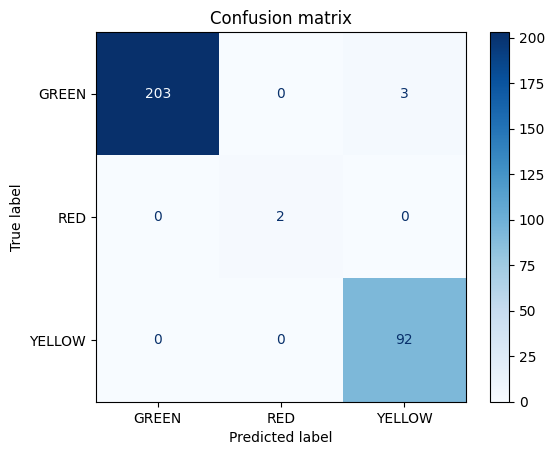

In [4]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt
pred = model.predict(X_te_n).argmax(axis=1)
print("Accuracy:", accuracy_score(y_te, pred))
print(classification_report(y_te, pred, target_names=le.classes_, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=le.classes_).plot(cmap="Blues")
plt.title("Confusion matrix"); plt.savefig("confusion_matrix.png", dpi=120); plt.show()

**Cell 5: Convert to TFLite with quantisation, then compare sizes (brief 2 and 3)**

Saved artifact at '/tmp/tmpugc0itw4'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  133541731692624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133541507286608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133541507286224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133541507286992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133541507286800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133541507286416: TensorSpec(shape=(), dtype=tf.resource, name=None)
Original: 27.2 KB, TFLite: 2.9 KB


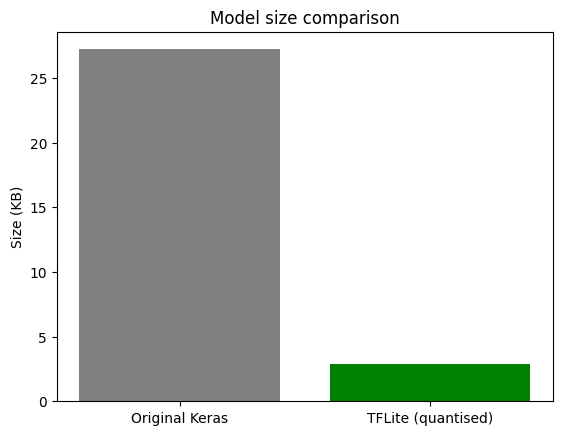

In [5]:
conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]          # quantisation
open("model.tflite", "wb").write(conv.convert())
orig, lite = os.path.getsize("model.keras")/1024, os.path.getsize("model.tflite")/1024
print(f"Original: {orig:.1f} KB, TFLite: {lite:.1f} KB")
plt.figure(); plt.bar(["Original Keras", "TFLite (quantised)"], [orig, lite], color=["grey", "green"])
plt.ylabel("Size (KB)"); plt.title("Model size comparison")
plt.savefig("model_size_comparison.png", dpi=120); plt.show()

**Cell 6: Download the files**

In [6]:
from google.colab import files
for f in ["model.tflite", "scaler.json", "confusion_matrix.png", "model_size_comparison.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>